## 1. Imports and configuration

In [1]:
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import ndimage
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42
LABEL_COL = "diagnosis_1"            # correct target: Benign / Malignant / Indeterminate (metadata.csv)
IMG_SIZE = (224, 224)
N_FOLDS = 7                          # 1 fold test, 1 fold validation, 5 folds train (~71/14/14)
REFIT_ON_TRAIN_PLUS_VAL = True       # final model is refit on train+val and tested once
np.random.seed(SEED)

## 2. Locate the project (works from `notebooks/` or from the root)

In [2]:
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "milk10k" / "metadata.csv").exists():
            return p
    raise FileNotFoundError("Could not find data/milk10k/metadata.csv above " + str(start))


ROOT = find_project_root()
DATA_DIR = ROOT / "data" / "milk10k"
IMG_DIR = DATA_DIR / "images"
OUT_DIR = ROOT / "outputs"
FIG_DIR = ROOT / "figures"
REP_DIR = ROOT / "reports"
for d in (OUT_DIR, FIG_DIR, REP_DIR):
    d.mkdir(exist_ok=True)

# isic_id -> file path (works whether images are flat or inside sub-folders)
image_index = {p.stem: p for p in IMG_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
print("Project root:", ROOT)
print("Images dir  :", IMG_DIR, "| exists:", IMG_DIR.exists(), "| images indexed:", len(image_index))

Project root: /Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification
Images dir  : /Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification/data/milk10k/images | exists: True | images indexed: 10480


## 3. Load data and **verify the target**

In [3]:
meta = pd.read_csv(DATA_DIR / "metadata.csv")
print("metadata shape:", meta.shape)
print("columns:", list(meta.columns))
print("image_type values:", meta["image_type"].unique())

assert LABEL_COL in meta.columns, f"{LABEL_COL} missing from metadata.csv"
meta = meta.dropna(subset=[LABEL_COL])

# one row per lesion: dermoscopic image only
df = meta[meta["image_type"].astype(str).str.contains("dermoscopic", case=False)].copy()

# keep only rows whose image file exists
exists = df["isic_id"].isin(image_index)
print(f"images found on disk: {exists.sum()} / {len(df)}")
df = df[exists].reset_index(drop=True)

print(f"\n>>> TARGET COLUMN: '{LABEL_COL}'")
print(df[LABEL_COL].value_counts())
print(df[LABEL_COL].value_counts(normalize=True).round(3))
print("rows:", len(df), "| unique lesions:", df["lesion_id"].nunique())

assert df["lesion_id"].is_unique, "expected exactly one dermoscopic image per lesion"
assert df[LABEL_COL].nunique() == 3, f"expected 3 classes, got {df[LABEL_COL].unique()}"

classes = np.array(sorted(df[LABEL_COL].unique()))
y = df[LABEL_COL].to_numpy()
groups = df["lesion_id"].to_numpy()
print("classes:", list(classes))

metadata shape: (10480, 17)
columns: ['isic_id', 'attribution', 'copyright_license', 'age_approx', 'anatom_site_general', 'anatom_site_special', 'concomitant_biopsy', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_4', 'diagnosis_confirm_type', 'image_manipulation', 'image_type', 'lesion_id', 'melanocytic', 'sex']
image_type values: <StringArray>
['dermoscopic', 'clinical: close-up']
Length: 2, dtype: str
images found on disk: 5240 / 5240

>>> TARGET COLUMN: 'diagnosis_1'
diagnosis_1
Malignant        3634
Benign           1483
Indeterminate     123
Name: count, dtype: int64
diagnosis_1
Malignant        0.694
Benign           0.283
Indeterminate    0.023
Name: proportion, dtype: float64
rows: 5240 | unique lesions: 5240
classes: [np.str_('Benign'), np.str_('Indeterminate'), np.str_('Malignant')]


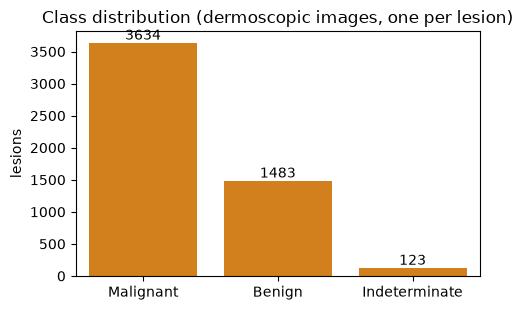

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.2))
order = df[LABEL_COL].value_counts().index
sns.countplot(data=df, x=LABEL_COL, order=order, color="#F08200", ax=ax)
for c in ax.containers:
    ax.bar_label(c)
ax.set_title("Class distribution (dermoscopic images, one per lesion)")
ax.set_xlabel(""); ax.set_ylabel("lesions")
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_class_distribution.png", dpi=150)
plt.show()

## 4. Feature extraction

| Block | Content | # |
|---|---|---|
| colour stats | mean / std of R, G, B | 6 |
| colour histogram | 8 bins x R, G, B (fractions) | 24 |
| texture | edge density (Sobel), roughness (9x9 local variance), Laplacian variance | 3 |
| extra | HSV mean/std, Sobel std / 95th pct / fraction>50, left-right and up-down asymmetry (the "A" of ABCDE) | 11 |

All images are resized to 224x224 first, so the vector length never depends on the image size.

In [5]:
def load_rgb(path):
    img = cv2.imread(str(path))
    if img is None:
        raise ValueError(f"cannot read {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)


def f_color_stats(img):
    flat = img.reshape(-1, 3).astype(np.float32)
    return np.concatenate([flat.mean(0), flat.std(0)])                         # 6


def f_histogram(img, bins=8):
    n = img.shape[0] * img.shape[1]
    return np.concatenate([np.histogram(img[:, :, c], bins=bins, range=(0, 256))[0] / n
                           for c in range(3)])                                 # 24


def f_texture(gray):
    gx, gy = ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0)
    edge_density = np.hypot(gx, gy).mean()
    local_var = ndimage.uniform_filter(gray ** 2, 9) - ndimage.uniform_filter(gray, 9) ** 2
    roughness = np.clip(local_var, 0, None).mean()
    lap_var = ndimage.laplace(gray).var()
    return np.array([edge_density, roughness, lap_var])                        # 3


def f_extra(img, gray):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).reshape(-1, 3).astype(np.float32)
    hsv_stats = np.concatenate([hsv.mean(0), hsv.std(0)])                      # 6
    mag = np.hypot(ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0))
    edge_extra = np.array([mag.std(), np.percentile(mag, 95), (mag > 50).mean()])   # 3
    h, w = gray.shape
    asym_lr = np.abs(gray[:, : w // 2] - gray[:, w - w // 2:][:, ::-1]).mean() / 255.0
    asym_ud = np.abs(gray[: h // 2] - gray[h - h // 2:][::-1]).mean() / 255.0
    return np.concatenate([hsv_stats, edge_extra, [asym_lr, asym_ud]])         # 11


def extract_all(path):
    img = load_rgb(path)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    return np.concatenate([f_color_stats(img), f_histogram(img), f_texture(gray), f_extra(img, gray)])


FEATURE_NAMES = (
    ["R_mean", "G_mean", "B_mean", "R_std", "G_std", "B_std"]
    + [f"hist_{c}_{i}" for c in "RGB" for i in range(8)]
    + ["edge_density", "roughness", "laplacian_var"]
    + ["H_mean", "S_mean", "V_mean", "H_std", "S_std", "V_std",
       "sobel_std", "sobel_p95", "sobel_frac50", "asym_lr", "asym_ud"]
)
assert len(FEATURE_NAMES) == 44

In [6]:
CACHE = OUT_DIR / "features_dermoscopic.npz"
X_all = None
if CACHE.exists():
    cached = np.load(CACHE, allow_pickle=True)
    if list(cached["ids"]) == list(df["isic_id"]) and cached["X"].shape[1] == len(FEATURE_NAMES):
        X_all = cached["X"]
        print("Loaded cached features:", X_all.shape)

if X_all is None:
    rows = []
    for i, isic_id in enumerate(df["isic_id"]):
        rows.append(extract_all(image_index[isic_id]))
        if (i + 1) % 500 == 0:
            print(f"  {i + 1}/{len(df)} images")
    X_all = np.vstack(rows)
    np.savez(CACHE, X=X_all, ids=df["isic_id"].to_numpy())
    print("Extracted features:", X_all.shape, "-> cached in", CACHE)

assert X_all.shape == (len(df), len(FEATURE_NAMES))
assert np.isfinite(X_all).all(), "NaN/inf in features"

FEATURE_SETS = {
    "color_stats": np.arange(0, 6),
    "histogram":   np.arange(6, 30),
    "texture":     np.arange(30, 33),
    "base_33":     np.arange(0, 33),     # the 33 numbers from the course
    "extended_44": np.arange(0, 44),     # + HSV, extra edge stats, asymmetry
}
pd.DataFrame(X_all, columns=FEATURE_NAMES).describe().T.head(12).round(2)

Loaded cached features: (5240, 44)


,count,mean,std,min,25%,50%,75%,max
R_mean,5240.0,170.74,23.71,67.31,154.12,167.90,188.16,251.92
G_mean,5240.0,138.82,19.73,46.90,127.00,138.86,151.31,235.88
B_mean,5240.0,136.92,21.54,43.84,124.59,136.15,148.21,231.80
R_std,5240.0,20.12,13.46,2.47,10.47,16.52,25.86,89.32
G_std,5240.0,25.20,13.10,5.19,15.63,21.53,31.99,83.13
B_std,5240.0,28.25,14.18,6.63,17.94,24.42,35.61,88.28
hist_R_0,5240.0,0.00,0.02,0.00,0.00,0.00,0.00,0.29
hist_R_1,5240.0,0.01,0.02,0.00,0.00,0.00,0.00,0.43
hist_R_2,5240.0,0.02,0.03,0.00,0.00,0.00,0.01,0.64
hist_R_3,5240.0,0.06,0.10,0.00,0.00,0.02,0.08,0.98


## 5. Leak-free split: grouped by `lesion_id`, stratified by diagnosis

In [7]:
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(X_all, y, groups)]
test_idx, val_idx = folds[0], folds[1]
train_idx = np.concatenate(folds[2:])

for a, b, name in [(train_idx, val_idx, "train/val"), (train_idx, test_idx, "train/test"), (val_idx, test_idx, "val/test")]:
    assert set(groups[a]).isdisjoint(groups[b]), f"LEAKAGE between {name}"
print("OK: no lesion_id shared between splits.")

split_counts = pd.DataFrame({
    "train": pd.Series(y[train_idx]).value_counts(),
    "val": pd.Series(y[val_idx]).value_counts(),
    "test": pd.Series(y[test_idx]).value_counts(),
}).fillna(0).astype(int)
print("\nLesions per split:")
display(split_counts)
print("Class proportions per split:")
display((split_counts / split_counts.sum()).round(3))
for c in classes:
    assert all(split_counts.loc[c] > 0), f"class {c} is missing from a split"

OK: no lesion_id shared between splits.

Lesions per split:


,train,val,test
Malignant,2595,519,520
Benign,1059,212,212
Indeterminate,88,18,17


Class proportions per split:


,train,val,test
Malignant,0.693,0.693,0.694
Benign,0.283,0.283,0.283
Indeterminate,0.024,0.024,0.023


## 6. Models

In [8]:
def make_models():
    return {
        "Majority": make_pipeline(DummyClassifier(strategy="most_frequent")),
        "LogReg (balanced)": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
        "kNN k=5": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "kNN k=15": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
        "RandomForest (balanced)": make_pipeline(
            RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   min_samples_leaf=2, n_jobs=-1, random_state=SEED)),
        "SVM-RBF (balanced)": make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=SEED)),
    }


list(make_models().keys())

['Majority',
 'LogReg (balanced)',
 'kNN k=5',
 'kNN k=15',
 'RandomForest (balanced)',
 'SVM-RBF (balanced)']

## 7. Model selection on the **validation** set

In [9]:
results = []
for fs_name, cols in FEATURE_SETS.items():
    Xtr, Xv = X_all[train_idx][:, cols], X_all[val_idx][:, cols]
    for m_name, model in make_models().items():
        model.fit(Xtr, y[train_idx])
        pred = model.predict(Xv)
        rec = recall_score(y[val_idx], pred, labels=classes, average=None, zero_division=0)
        row = {"feature_set": fs_name, "model": m_name,
               "val_accuracy": accuracy_score(y[val_idx], pred),
               "val_macro_f1": f1_score(y[val_idx], pred, average="macro", zero_division=0)}
        row.update({f"recall_{c}": r for c, r in zip(classes, rec)})
        results.append(row)

val_results = (pd.DataFrame(results)
               .sort_values("val_macro_f1", ascending=False)
               .reset_index(drop=True))
val_results.to_csv(OUT_DIR / "baseline_validation_results.csv", index=False)

majority_f1 = val_results.loc[val_results["model"] == "Majority", "val_macro_f1"].max()
print(f"Majority-class floor (validation macro-F1): {majority_f1:.3f}")
display(val_results.round(3))

Majority-class floor (validation macro-F1): 0.273


,feature_set,model,val_accuracy,val_macro_f1,recall_Benign,recall_Indeterminate,recall_Malignant
0,extended_44,RandomForest (balanced),0.776,0.560,0.575,0.167,0.879
1,base_33,RandomForest (balanced),0.762,0.542,0.547,0.167,0.871
2,histogram,RandomForest (balanced),0.764,0.529,0.542,0.111,0.877
3,extended_44,SVM-RBF (balanced),0.649,0.497,0.604,0.556,0.671
4,color_stats,RandomForest (balanced),0.696,0.486,0.524,0.167,0.784
5,extended_44,kNN k=5,0.724,0.486,0.368,0.111,0.890
6,base_33,SVM-RBF (balanced),0.614,0.472,0.590,0.500,0.628
7,extended_44,LogReg (balanced),0.559,0.451,0.580,0.722,0.545
8,color_stats,kNN k=5,0.702,0.448,0.410,0.056,0.844
9,base_33,LogReg (balanced),0.550,0.442,0.618,0.556,0.522


Selected on VALIDATION: features='extended_44', model='RandomForest (balanced)', macro-F1=0.560 (floor 0.273)


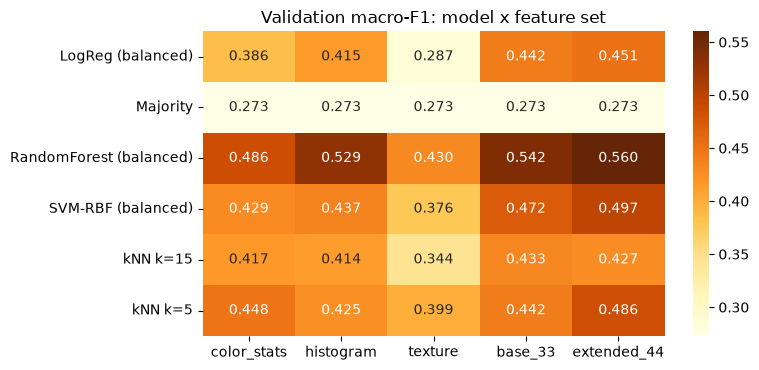

In [10]:
best = val_results.iloc[0]
BEST_FS, BEST_MODEL = best["feature_set"], best["model"]
print(f"Selected on VALIDATION: features='{BEST_FS}', model='{BEST_MODEL}', "
      f"macro-F1={best['val_macro_f1']:.3f} (floor {majority_f1:.3f})")

pivot = val_results.pivot(index="model", columns="feature_set", values="val_macro_f1")[list(FEATURE_SETS)]
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlOrBr", ax=ax)
ax.set_title("Validation macro-F1: model x feature set"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_validation_heatmap.png", dpi=150)
plt.show()

In [11]:
cols = FEATURE_SETS[BEST_FS]
final_model = make_models()[BEST_MODEL]
fit_idx = np.concatenate([train_idx, val_idx]) if REFIT_ON_TRAIN_PLUS_VAL else train_idx
final_model.fit(X_all[fit_idx][:, cols], y[fit_idx])
test_pred = final_model.predict(X_all[test_idx][:, cols])
y_test = y[test_idx]

test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)
test_recall = {str(c): float(r) for c, r in zip(classes, recall_score(y_test, test_pred, labels=classes, average=None, zero_division=0))}

print("=" * 60)
print(f"Config        : {BEST_FS} + {BEST_MODEL}")
print(f"TEST accuracy : {test_acc:.4f}")
print(f"TEST macro-F1 : {test_f1:.4f}")
print("TEST recall   :", {k: round(float(v), 3) for k, v in test_recall.items()})
print("=" * 60)
test_report_txt = classification_report(y_test, test_pred, labels=classes, zero_division=0)
print(test_report_txt)

# sanity: what would "always Malignant" have scored on this same test set?
maj_pred = np.full_like(y_test, pd.Series(y[train_idx]).value_counts().index[0])
print("Majority-class test macro-F1 (reference):",
      round(f1_score(y_test, maj_pred, average="macro", zero_division=0), 4))

Config        : extended_44 + RandomForest (balanced)
TEST accuracy : 0.7543
TEST macro-F1 : 0.5034
TEST recall   : {'Benign': 0.552, 'Indeterminate': 0.059, 'Malignant': 0.86}
               precision    recall  f1-score   support

       Benign       0.62      0.55      0.58       212
Indeterminate       0.25      0.06      0.10        17
    Malignant       0.80      0.86      0.83       520

     accuracy                           0.75       749
    macro avg       0.56      0.49      0.50       749
 weighted avg       0.74      0.75      0.74       749

Majority-class test macro-F1 (reference): 0.2732


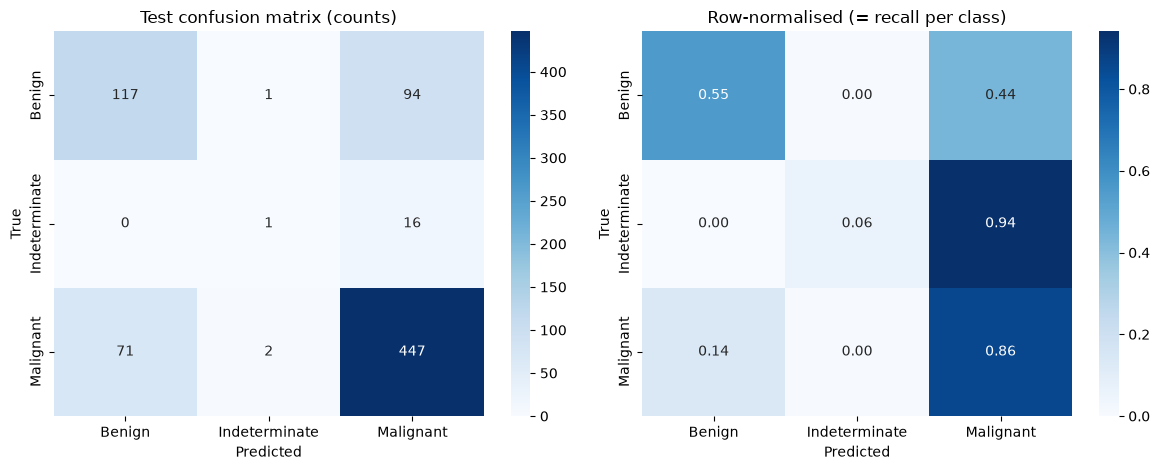

In [12]:
cm = confusion_matrix(y_test, test_pred, labels=classes)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Test confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title("Row-normalised (= recall per class)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_confusion_matrix_test.png", dpi=150)
plt.show()

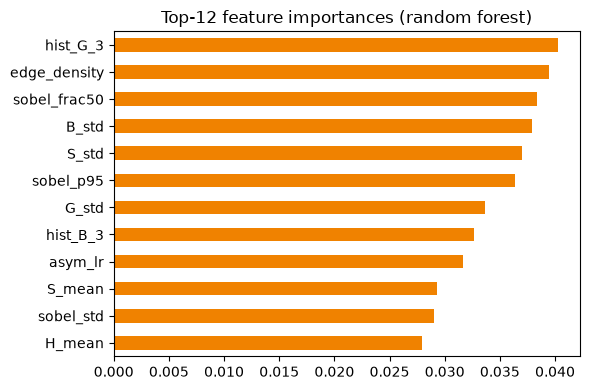

In [13]:
# which features did the model use? (only for tree-based winners)
rf = final_model[-1]
if hasattr(rf, "feature_importances_"):
    names = [FEATURE_NAMES[i] for i in cols]
    imp = pd.Series(rf.feature_importances_, index=names).sort_values(ascending=False).head(12)
    fig, ax = plt.subplots(figsize=(6, 4))
    imp[::-1].plot(kind="barh", color="#F08200", ax=ax)
    ax.set_title("Top-12 feature importances (random forest)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "baseline_feature_importance.png", dpi=150)
    plt.show()
else:
    print("Selected model has no feature_importances_; skipping.")

In [14]:
def md_table(d, nd=3):
    cols_ = list(d.columns)
    lines = ["| " + " | ".join(cols_) + " |", "|" + "|".join(["---"] * len(cols_)) + "|"]
    for _, r in d.iterrows():
        cells_ = [f"{v:.{nd}f}" if isinstance(v, (float, np.floating)) else str(v) for v in r]
        lines.append("| " + " | ".join(cells_) + " |")
    return "\n".join(lines)


cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in classes], columns=[f"pred {c}" for c in classes]).reset_index()
cm_df = cm_df.rename(columns={"index": ""})

report = f"""# Baseline results (auto-generated)

Target: `{LABEL_COL}` | classes: {list(classes)} | lesions: {len(df)} | features: {X_all.shape[1]} (sets: {list(FEATURE_SETS)})
Split (grouped by lesion_id, stratified): train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)}

## Lesions per split
{md_table(split_counts.reset_index().rename(columns={"index": "class"}), 0)}

## Validation (top 10 by macro-F1)
{md_table(val_results.head(10))}

Majority-class floor (val macro-F1): {majority_f1:.3f}

## Selected configuration
features = `{BEST_FS}`, model = `{BEST_MODEL}`, validation macro-F1 = {best['val_macro_f1']:.3f}

## Test (evaluated once)
accuracy = {test_acc:.4f} | macro-F1 = {test_f1:.4f}
recall per class = {{{", ".join(f"{k}: {v:.3f}" for k, v in test_recall.items())}}}

```
{test_report_txt}
```

Confusion matrix (rows = truth):
{md_table(cm_df, 0)}

Figures: figures/baseline_confusion_matrix_test.png, figures/baseline_validation_heatmap.png
"""
(REP_DIR / "baseline_results.md").write_text(report)
test_summary = {"features": BEST_FS, "model": BEST_MODEL, "val_macro_f1": float(best["val_macro_f1"]),
                "test_accuracy": float(test_acc), "test_macro_f1": float(test_f1),
                "test_recall": {k: float(v) for k, v in test_recall.items()}}
(OUT_DIR / "baseline_test_summary.json").write_text(json.dumps(test_summary, indent=2))
print("Saved:", REP_DIR / "baseline_results.md")
print(json.dumps(test_summary, indent=2))

Saved: /Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification/reports/baseline_results.md
{
  "features": "extended_44",
  "model": "RandomForest (balanced)",
  "val_macro_f1": 0.5601264420987706,
  "test_accuracy": 0.7543391188251002,
  "test_macro_f1": 0.5034405535659018,
  "test_recall": {
    "Benign": 0.5518867924528302,
    "Indeterminate": 0.058823529411764705,
    "Malignant": 0.8596153846153847
  }
}


In [15]:
# ---- 1. The chosen configuration (selected on VALIDATION) ----
est = final_model[-1]                                   # last step of the pipeline = the classifier
class_weight = est.get_params().get("class_weight", "not available (this model has no class_weight)")
print("=" * 70)
print(f"Selected on VALIDATION : features = '{best['feature_set']}', model = '{best['model']}'")
print(f"Validation macro-F1    : {best['val_macro_f1']:.3f}   (validation accuracy {best['val_accuracy']:.3f})")
print(f"class_weight used      : {class_weight}")
print(f"Final fit on           : {'train + validation' if REFIT_ON_TRAIN_PLUS_VAL else 'train only'}")
if class_weight != "balanced":
    print("NOTE: this model does NOT use class_weight='balanced' - say so in the report.")

# ---- 2. Test results (test set used once) ----
y_test_ = y[test_idx]
test_acc_ = accuracy_score(y_test_, test_pred)
test_f1_ = f1_score(y_test_, test_pred, average="macro", zero_division=0)
rec_ = recall_score(y_test_, test_pred, labels=classes, average=None, zero_division=0)
print("-" * 70)
print(f"TEST accuracy : {test_acc_:.4f}")
print(f"TEST macro-F1 : {test_f1_:.4f}")
for c, r, n in zip(classes, rec_, [(y_test_ == c).sum() for c in classes]):
    print(f"  recall {c:14s}: {r:.3f}   ({int(round(r * n))} of {n})")

# ---- 3. Reference points ----
maj_class = pd.Series(y[train_idx]).value_counts().index[0]
maj_pred = np.full_like(y_test_, maj_class)
maj_acc = accuracy_score(y_test_, maj_pred)
maj_f1 = f1_score(y_test_, maj_pred, average="macro", zero_division=0)
print("-" * 70)
print(f"Majority-class baseline ('{maj_class}' always): accuracy {maj_acc:.3f}, macro-F1 {maj_f1:.3f}")
comparison = pd.DataFrame({"val macro-F1": [0.534, best["val_macro_f1"]],
                           "test macro-F1": [0.495, test_f1_]},
                          index=["Course reference (random forest)", "Mine"]).round(3)
print(comparison.to_string())

# ---- 4. Top of the validation table ----
print("-" * 70)
print("Top 5 validation results:")
print(val_results.head(5).round(3)[["feature_set", "model", "val_accuracy", "val_macro_f1"]].to_string(index=False))

# ---- 5. Save everything for the written report ----
summary = f"""# Session 5 - baseline summary

- Target: diagnosis_1 ({', '.join(map(str, classes))})
- Selected on validation: features = {best['feature_set']}, model = {best['model']}, val macro-F1 = {best['val_macro_f1']:.3f}
- class_weight: {class_weight}
- Test accuracy: {test_acc_:.4f} | Test macro-F1: {test_f1_:.4f}
- Test recall: {', '.join(f'{c}: {r:.3f}' for c, r in zip(classes, rec_))}
- Majority-class baseline: accuracy {maj_acc:.3f}, macro-F1 {maj_f1:.3f}
- Course reference (random forest): val 0.534, test 0.495
"""
(OUT_DIR / "session5_summary.md").write_text(summary)
print("\nSaved:", OUT_DIR / "session5_summary.md")

Selected on VALIDATION : features = 'extended_44', model = 'RandomForest (balanced)'
Validation macro-F1    : 0.560   (validation accuracy 0.776)
class_weight used      : balanced
Final fit on           : train + validation
----------------------------------------------------------------------
TEST accuracy : 0.7543
TEST macro-F1 : 0.5034
  recall Benign        : 0.552   (117 of 212)
  recall Indeterminate : 0.059   (1 of 17)
  recall Malignant     : 0.860   (447 of 520)
----------------------------------------------------------------------
Majority-class baseline ('Malignant' always): accuracy 0.694, macro-F1 0.273
                                  val macro-F1  test macro-F1
Course reference (random forest)         0.534          0.495
Mine                                     0.560          0.503
----------------------------------------------------------------------
Top 5 validation results:
feature_set                   model  val_accuracy  val_macro_f1
extended_44 RandomForest (bal

## 1. Task and correction after feedback

The goal is to predict the top-level diagnosis of a skin lesion (`diagnosis_1`: Benign, Indeterminate or Malignant) from a dermoscopic image, using handcrafted image features and classical machine-learning models.

In my first submission the code did not find the label in `training_gt.csv` and fell back to the `AKIEC` column, so the model solved "AKIEC vs rest": 92 % accuracy, but only 1 of 118 positives found. In this version the target is `diagnosis_1` from `metadata.csv`, the target and its class counts are printed and asserted in the code, `class_weight="balanced"` is used wherever the model supports it, and the confusion matrix is checked.

## 2. Data and split

The dataset has 5,240 lesions, each with one dermoscopic image: 69.4 % Malignant, 28.3 % Benign and only 2.3 % Indeterminate. It is imbalanced, so accuracy alone is misleading and macro-F1 and per-class recall are reported.

The metadata lists 10,480 images (two per lesion). Only the dermoscopic image is used, so there is exactly one row per lesion, and all 5,240 image files were found on disk. The split uses `StratifiedGroupKFold` (7 folds, seed 42): one fold for test, one for validation and five for training. It is grouped by `lesion_id`, and the code asserts that no lesion appears in two sets. It is stratified by diagnosis, so the class proportions are the same in every set.

| Class | Total | Train | Validation | Test |
| --- | --- | --- | --- | --- |
| Malignant | 3,634 | 2,595 | 519 | 520 |
| Benign | 1,483 | 1,059 | 212 | 212 |
| Indeterminate | 123 | 88 | 18 | 17 |
| Total | 5,240 | 3,742 | 749 | 749 |

## 3. Features and models

Five feature sets and six models were compared, and the best combination was chosen on validation macro-F1. All features are computed from the image resized to 224×224 pixels.

| Feature set | Content | Features |
| --- | --- | --- |
| color_stats | mean and standard deviation of R, G, B | 6 |
| histogram | 8-bin histogram for each of R, G, B | 24 |
| texture | edge density (Sobel), roughness (9×9 local variance), Laplacian variance | 3 |
| base_33 | color_stats + histogram + texture (the course's 33 numbers) | 33 |
| extended_44 | base_33 + HSV mean/std, extra edge statistics, left-right and up-down asymmetry | 44 |

Models: majority class (baseline), logistic regression, kNN (k = 5 and k = 15), random forest (300 trees) and SVM with RBF kernel. `class_weight="balanced"` is used for logistic regression, random forest and SVM; kNN and the majority baseline have no such option. Features are standardised with a scaler fitted on the training data only (inside a scikit-learn pipeline).

Protocol: every model and feature set is trained on the training set and compared on the validation set by macro-F1. The chosen configuration is then refit on train + validation and evaluated once on the test set.

## 4. Validation results

The best configuration on validation is extended_44 with a random forest (balanced), with a macro-F1 of 0.560 against 0.273 for the majority class. Of the 30 combinations tried, the top ones are:

| Features | Model | Val accuracy | Val macro-F1 | Recall Benign | Recall Indeterminate | Recall Malignant |
| --- | --- | --- | --- | --- | --- | --- |
| extended_44 | Random forest (balanced) | 0.776 | **0.560** | 0.575 | 0.167 | 0.879 |
| base_33 | Random forest (balanced) | 0.762 | 0.542 | 0.547 | 0.167 | 0.871 |
| histogram | Random forest (balanced) | 0.764 | 0.529 | 0.542 | 0.111 | 0.877 |
| extended_44 | SVM-RBF (balanced) | 0.649 | 0.497 | 0.604 | 0.556 | 0.671 |
| extended_44 | Logistic regression (balanced) | 0.559 | 0.451 | 0.580 | 0.722 | 0.545 |
| any | Majority class | 0.693 | 0.273 | 0.000 | 0.000 | 1.000 |

The richer 44-feature set beat the course's 33 features (0.560 vs 0.542), and random forests took four of the top five places. SVM and logistic regression recognise Indeterminate much better (recall 0.56 to 0.72) but lose Malignant recall (0.55 to 0.67), so macro-F1 favoured the forest.

## 5. Test results (evaluated once)

On the 749 test lesions the selected model reaches an accuracy of 0.754 and a macro-F1 of 0.503. The majority-class baseline gets accuracy 0.694 and macro-F1 0.273, so the model is clearly better, and it finds 447 of the 520 malignant lesions.

| Class | Precision | Recall | F1 | Support |
| --- | --- | --- | --- | --- |
| Benign | 0.62 | 0.55 | 0.58 | 212 |
| Indeterminate | 0.25 | 0.06 | 0.10 | 17 |
| Malignant | 0.80 | 0.86 | 0.83 | 520 |
| Macro average | 0.56 | 0.49 | 0.50 | 749 |

Confusion matrix (rows = true class, columns = predicted class):

| True \ Predicted | Benign | Indeterminate | Malignant |
| --- | --- | --- | --- |
| Benign | 117 | 1 | 94 |
| Indeterminate | 0 | 1 | 16 |
| Malignant | 71 | 2 | 447 |

The figure is saved in the repository as `figures/confusion_matrix_test.png`.

## 6. Discussion

The baseline works: macro-F1 is 0.503 on test against 0.273 for always predicting Malignant, in line with the course reference for a random forest (0.534 validation, 0.495 test; mine: 0.560 and 0.503). Unlike the first submission, which found 1 of 118 positives, the model now recognises most Malignant lesions and about half of the Benign ones.

- **Clinical risk.** 71 of 520 malignant lesions (14 %) are classified as benign. A missed malignancy is the costly error, so Malignant recall (0.86) matters more than accuracy. In the other direction, 94 of 212 benign lesions (44 %) are called malignant, which means unnecessary biopsies.
- **Indeterminate class.** Only 1 of 17 Indeterminate test lesions is found (recall 0.06); 16 are predicted Malignant. The class has just 123 lesions (2.3 %), and the validation and test sets contain only 18 and 17 of them, so these estimates are very noisy. Logistic regression and SVM recognised the class far better on validation, but at the cost of Malignant recall, so macro-F1 chose the forest.
- **Validation vs test.** Macro-F1 drops from 0.560 to 0.503. Part of the gap comes from picking the best of 30 configurations on a small validation set, so the validation score is slightly optimistic.

### Limitations and next steps

- Whole-image handcrafted features mix hair, skin tone and background with the lesion, and there is no lesion mask.
- A single split and a very small rare class: differences of about 0.02 in macro-F1 should not be over-interpreted.
- Next: the neural network of Session 6 on the same features, and convolutional networks that learn features directly from the pixels, to be compared with this baseline.